<a href="https://colab.research.google.com/github/w2259108/arclight/blob/main/Vincent_Casaceli_M06_11_H01_Lab_NLP_Students.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab - NLP Module 06

## Lab Summary:

In this lab we will be discussing about Neural Networks.
## Lab Goal:
Upon completion of this lab, the student should be able to:
<ul>
    <li> design neural networks and use them for simple applications </li>
    
</ul>


## Time Requried:
This lab should take 1.5 hours to complete for those unfamiliar with the tools.
Hint: The lab flow is already prepared for you, just read through the links and try implementing them. Don't try to have it all figured out before starting.

## Lab Preparation:
<ul>
    <li> Review Lectures for Module06</li>
</ul>

## Hardware Needed:
Any computer with access to the internet and web browser



## Import Packages and Classes (Initial)

In this lab we will be using the following libraries:
<ol>
    <li> NLTK </li>
    <li> Pandas </li>
    <li> Matplotlib </li>
    <li> Keras </li>
</ol>


<b>Matplotlib</b> Matplotlib is a comprehensive library for creating static, animated, and interactive visualizations in Python. It is completely free and open source.

![Image](https://miro.medium.com/max/1050/1*EsqDYFK-IzGEAm4FyZP0wQ.jpeg)

More here: https://matplotlib.org/stable/index.

<b>Pandas</b> is a fast, powerful, flexible and easy to use open source data analysis and manipulation tool, built on top of the Python programming language.

![Image](https://miro.medium.com/max/819/1*Dss7A8Z-M4x8LD9ccgw7pQ.png)

More here: https://pandas.pydata.org/

<b>Gensim</b> supports a variety of other NLP tasks such as:
- converting words to vectors (word2vec),
- document to vectors (doc2vec),
- finding text similarity, and text summarization

![Gensim](https://repository-images.githubusercontent.com/1349775/202c4680-8f7c-11e9-91c6-745fdcbeffe8)

More about Gensim here:
https://pypi.org/project/gensim/

<b>Keras</b> is an open source library that provides a lot of functionalities for designing neural networks.

![Keras](https://keras.io/img/logo.png)

More about Keras here: https://keras.io/

#Neural Networks

Neural networks are multi-layer networks of neuronsthat we use to classify things, make predictions, etc. Below is the diagram of a simple neural network with one input layer, one output layer and one hidden layers of neuron.

![Image](https://ars.els-cdn.com/content/image/3-s2.0-B9780128115299000017-f01-07-9780128115299.jpg)

Now, we will design and view a simple neural network using Keras.

Keras is an open-source software library that provides a Python interface for artificial neural networks.

Now, the first thing is the dataset. We would use the scikit learn library to create a dataset for ourselves. The dataset would have 10 columns and 2 target classes. So, we would be training our classifier to learn to distinguish between 2 classes.

In [1]:
# Create dataset (execute this cell) (0.5 Points)
from sklearn.datasets import make_classification
import pandas as pd
# Creating the dataset
# CELL 1
# running as is no changes
X, y = make_classification(n_samples = 500,
                                       n_features = 10,
                                       n_informative = 5,
                                       n_redundant = 0,
                                       n_classes = 2,
                                       weights = [.2, .3])

# Viewing the dataset
print("Dataset: ");
print(pd.DataFrame(X, columns=["Feature 1", "Feature 2", "Feature 3", "Feature 4", "Feature 5","Feature 6", "Feature 7", "Feature 8", "Feature 9", "Feature 10"]).head())

Dataset: 
   Feature 1  Feature 2  Feature 3  Feature 4  Feature 5  Feature 6  \
0  -2.368378   1.412254  -1.285438  -0.698110  -0.024470  -0.270020   
1   0.125393  -2.036440   0.107970   1.639756  -0.064131  -0.593080   
2   0.984368  -0.193208   0.970636   0.450299  -1.720222  -2.426241   
3   0.128016  -0.386241   1.955315  -0.984478   0.411039  -0.582216   
4  -0.906294  -1.981347  -0.431472  -0.545162  -0.227343   1.980225   

   Feature 7  Feature 8  Feature 9  Feature 10  
0   0.236603   0.354109   0.897331    0.318164  
1  -1.426717  -1.081896  -3.182540    3.798517  
2  -0.431232   1.069195  -0.507985    0.383846  
3  -1.440733  -1.538008   0.004876   -0.831376  
4  -0.633099  -0.853689  -1.577289    3.195698  


#Splitting into train and test set



In [3]:
# Train/Test Split (1.0 Points)
# CELL 2
# one line for splitting dataset
# your task is to split the dataset such that there is 80% training data and 20% test data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


(400, 10) (100, 10) (400,) (100,)


#Designing the Neural Network

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


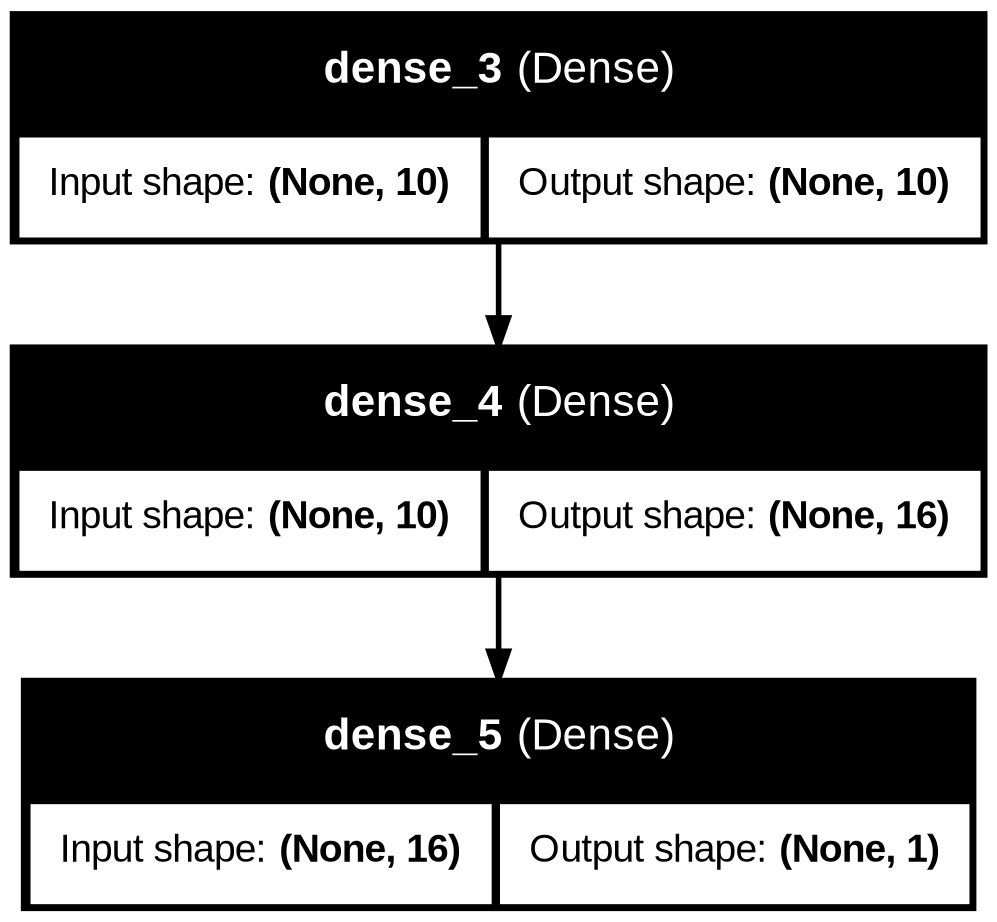

In [5]:
# Build the Model (execute this cell) (0.5 Points)
# CELL 3
# ignoring error message output as expected
# Importing the Keras libraries and packages
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.utils import plot_model

# Initialising the Neural Network
model = Sequential()

# Adding the input layer and the first hidden layer
model.add(Dense(units = 10, kernel_initializer = 'uniform', activation = 'relu', input_dim = 10))

# Adding the second hidden layer
model.add(Dense(units = 16, kernel_initializer = 'uniform', activation = 'relu'))

# Adding the output layer
model.add(Dense(units = 1, kernel_initializer = 'uniform', activation = 'sigmoid'))

# Compiling the ANN
model.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

plot_model(model, to_file='model_plot.png', show_shapes=True, show_layer_names=True)

In [6]:
# Train the Model (execute this cell) (0.5 Points)
# CELL 4
# run only - no changes
# Fitting the Neural Network to the Training set
model.fit(X_train, y_train, batch_size = 10, epochs = 100)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5525 - loss: 0.6912
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8050 - loss: 0.6711
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8375 - loss: 0.5867
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8775 - loss: 0.4474
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8875 - loss: 0.3413
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8950 - loss: 0.2867
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9050 - loss: 0.2592
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9050 - loss: 0.2426
Epoch 9/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9050 - loss: 0.2324
Epoch 10/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9125 - loss: 0.2249
Epoch 11/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9125 - loss: 0.2177
Epoch 12/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy:

#Task

We would create a dataset for you with 20 input features and 2 output classes. Your task is to design a neural network with an input layer, 2 hidden layers with 32 neurons and an output layer that can classify into 2 classes.

In [7]:
# Create the dataset (execute this cell) (0.5 Points)
# CELL 5
X, y = make_classification(n_samples = 500,
                                       n_features = 20,
                                       n_informative = 5,
                                       n_redundant = 0,
                                       n_classes = 2,
                                       weights = [.3, .421])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


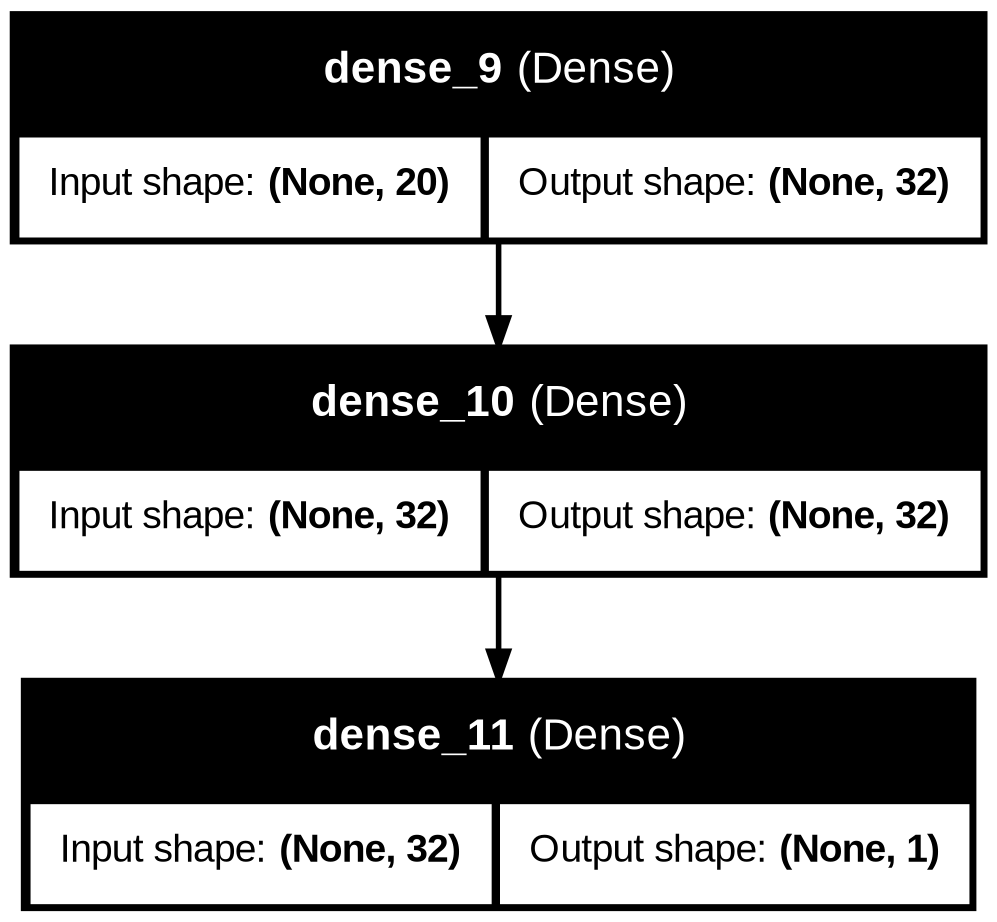

In [9]:
# TODO: Fix this representation
# CELL 6
# creating and compliing model
# error ignored warning only, deprication message
# Create the Model (2.0 Points)
model = Sequential()
model.add(Dense(units=32, kernel_initializer='uniform', activation='relu', input_dim=20))
model.add(Dense(units=32, kernel_initializer='uniform', activation='relu'))
model.add(Dense(units=1, kernel_initializer='uniform', activation='sigmoid'))
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
plot_model(model, to_file='model_plot.png', show_shapes=True, show_layer_names=True)


#Activation functions

- Helps the artificial neural network learn complex patterns in the data

- input into the activation function is W*x + b where W is the weights of the cell and the x is the inputs and then there is the bias b added to that. This value if not restricted to a certain limit can go very high in magnitude

- ability to add non-linearity into a neural network.

![Activation Function](https://miro.medium.com/max/1200/1*ZafDv3VUm60Eh10OeJu1vw.png)


Also see: https://www.youtube.com/watch?v=SXrXUqDjICA

#Learning Rate

- The learning rate is a hyperparameter that controls how much to change the model in response to the estimated error each time the model weights are updated

- a value of learning rate too small may result in a long training process that could get stuck

- a value of learning rate too large may result in not obtaining optimal parameter values

![LR](https://www.jeremyjordan.me/content/images/2018/02/Screen-Shot-2018-02-24-at-11.47.09-AM.png)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


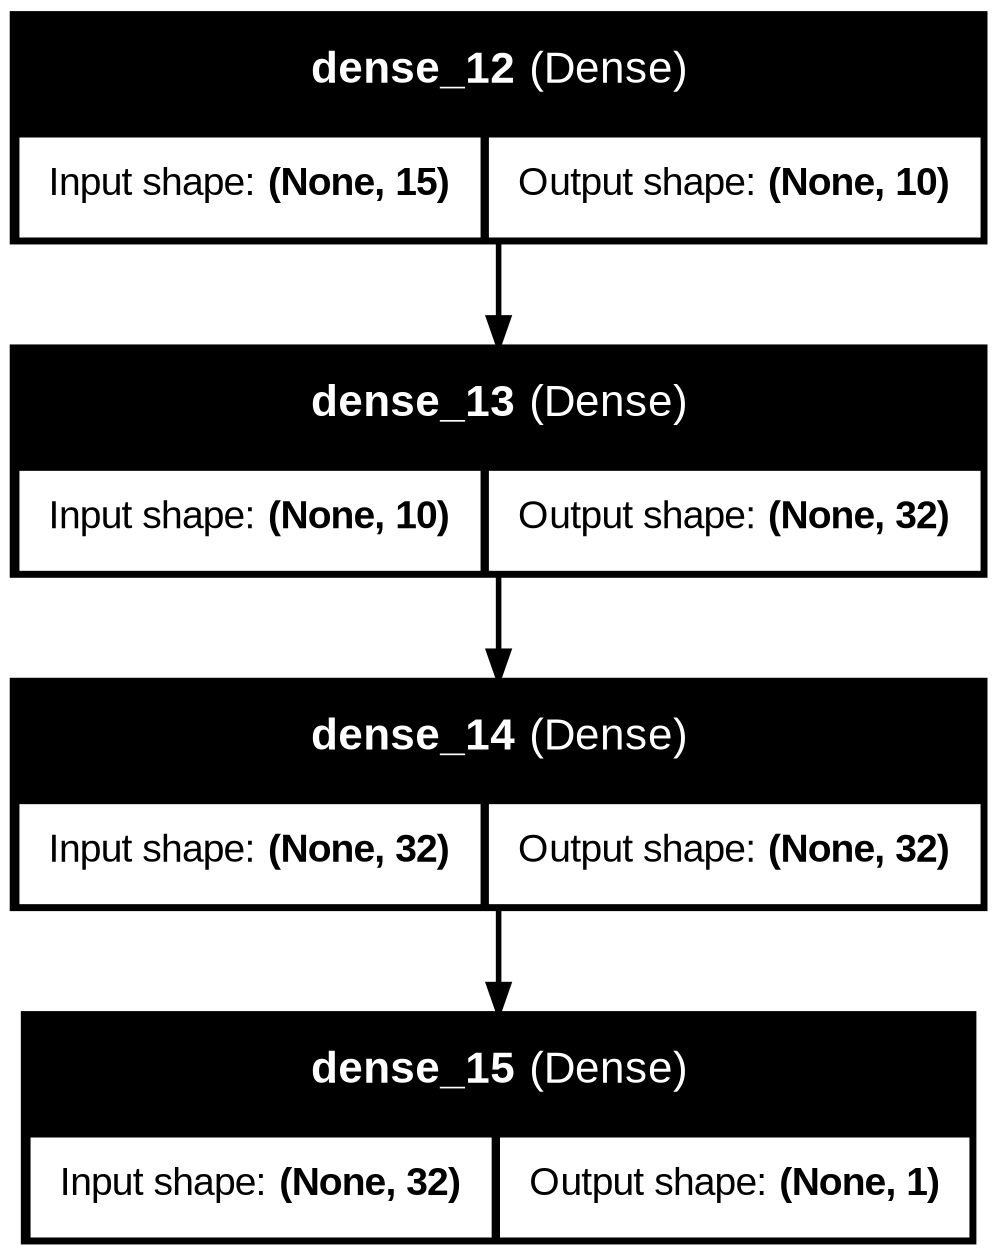

In [10]:
# Create the dataset and model (execute this cell) (0.5 Points)
# CELL 7
# Run only
X, y = make_classification(n_samples = 500,
                                       n_features = 15,
                                       n_informative = 5,
                                       n_redundant = 0,
                                       n_classes = 2,
                                       weights = [.3, .421])

model3 = Sequential()
model3.add(Dense(units = 10, kernel_initializer = 'uniform', activation = 'relu', input_dim = 15))
model3.add(Dense(units = 32, kernel_initializer = 'uniform', activation = 'relu'))
model3.add(Dense(units = 32, kernel_initializer = 'uniform', activation = 'relu'))
model3.add(Dense(units = 1, kernel_initializer = 'uniform', activation = 'sigmoid'))
model3.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])
plot_model(model3, to_file='model_plot.png', show_shapes=True, show_layer_names=True)

Now, make the following modifications to the model: 'model3'

- Change the activation functions to tanh (apart from last layer)

- Add 2 more layers after the input layer with 24 and 48 neurons

- Change the learning rate to SGD, RMSprop

Visulaize the neural network at every step.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


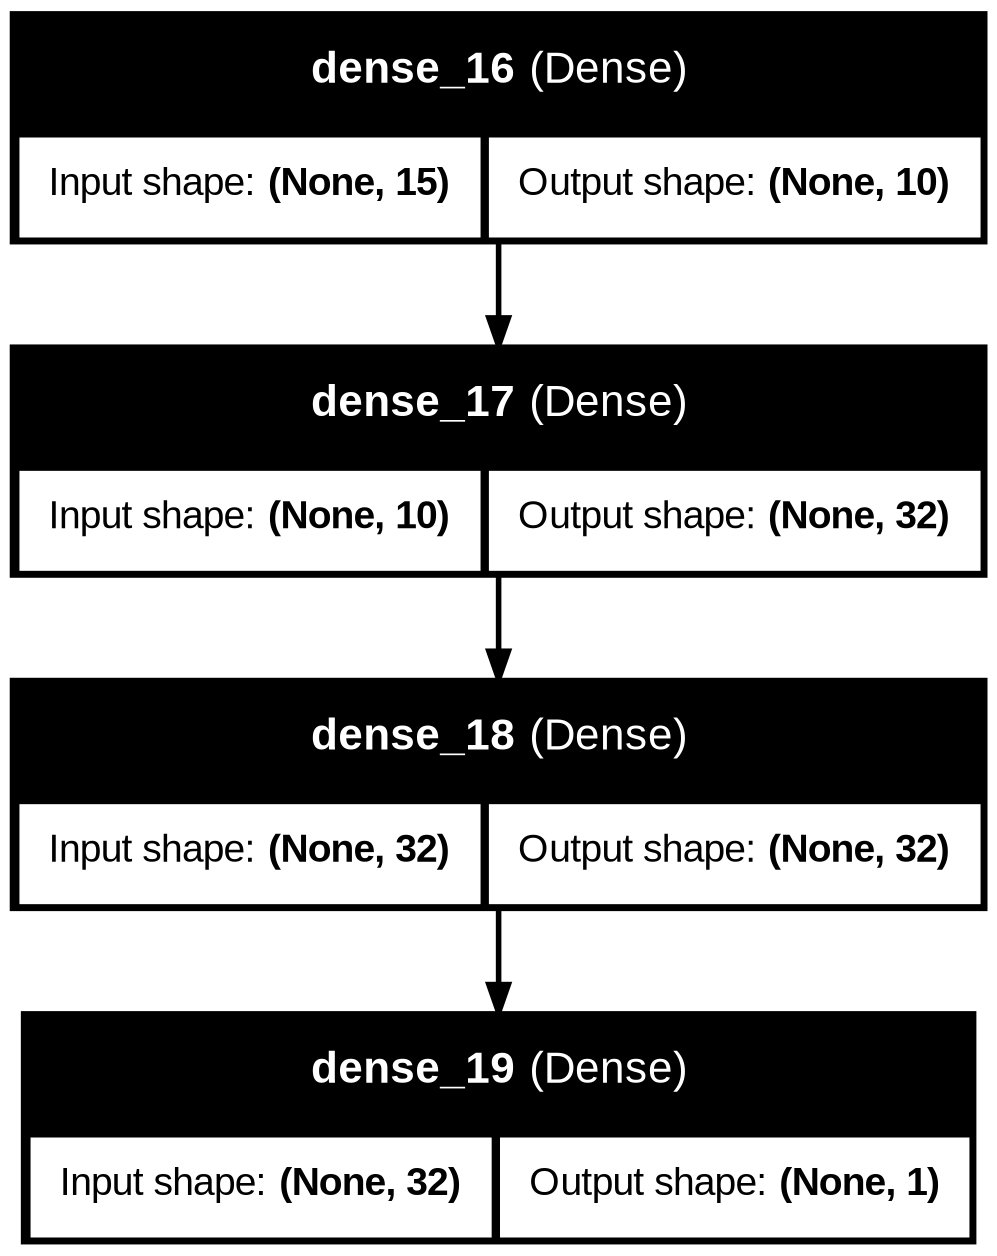

In [11]:
# Change activation functions to tanh (1.0 Points)
# CELL 8
# Adding to model
model3 = Sequential()
model3.add(Dense(units=10, kernel_initializer='uniform', activation='tanh', input_dim=15))
model3.add(Dense(units=32, kernel_initializer='uniform', activation='tanh'))
model3.add(Dense(units=32, kernel_initializer='uniform', activation='tanh'))
model3.add(Dense(units=1, kernel_initializer='uniform', activation='sigmoid'))
model3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
plot_model(model3, to_file='model_plot.png', show_shapes=True, show_layer_names=True)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


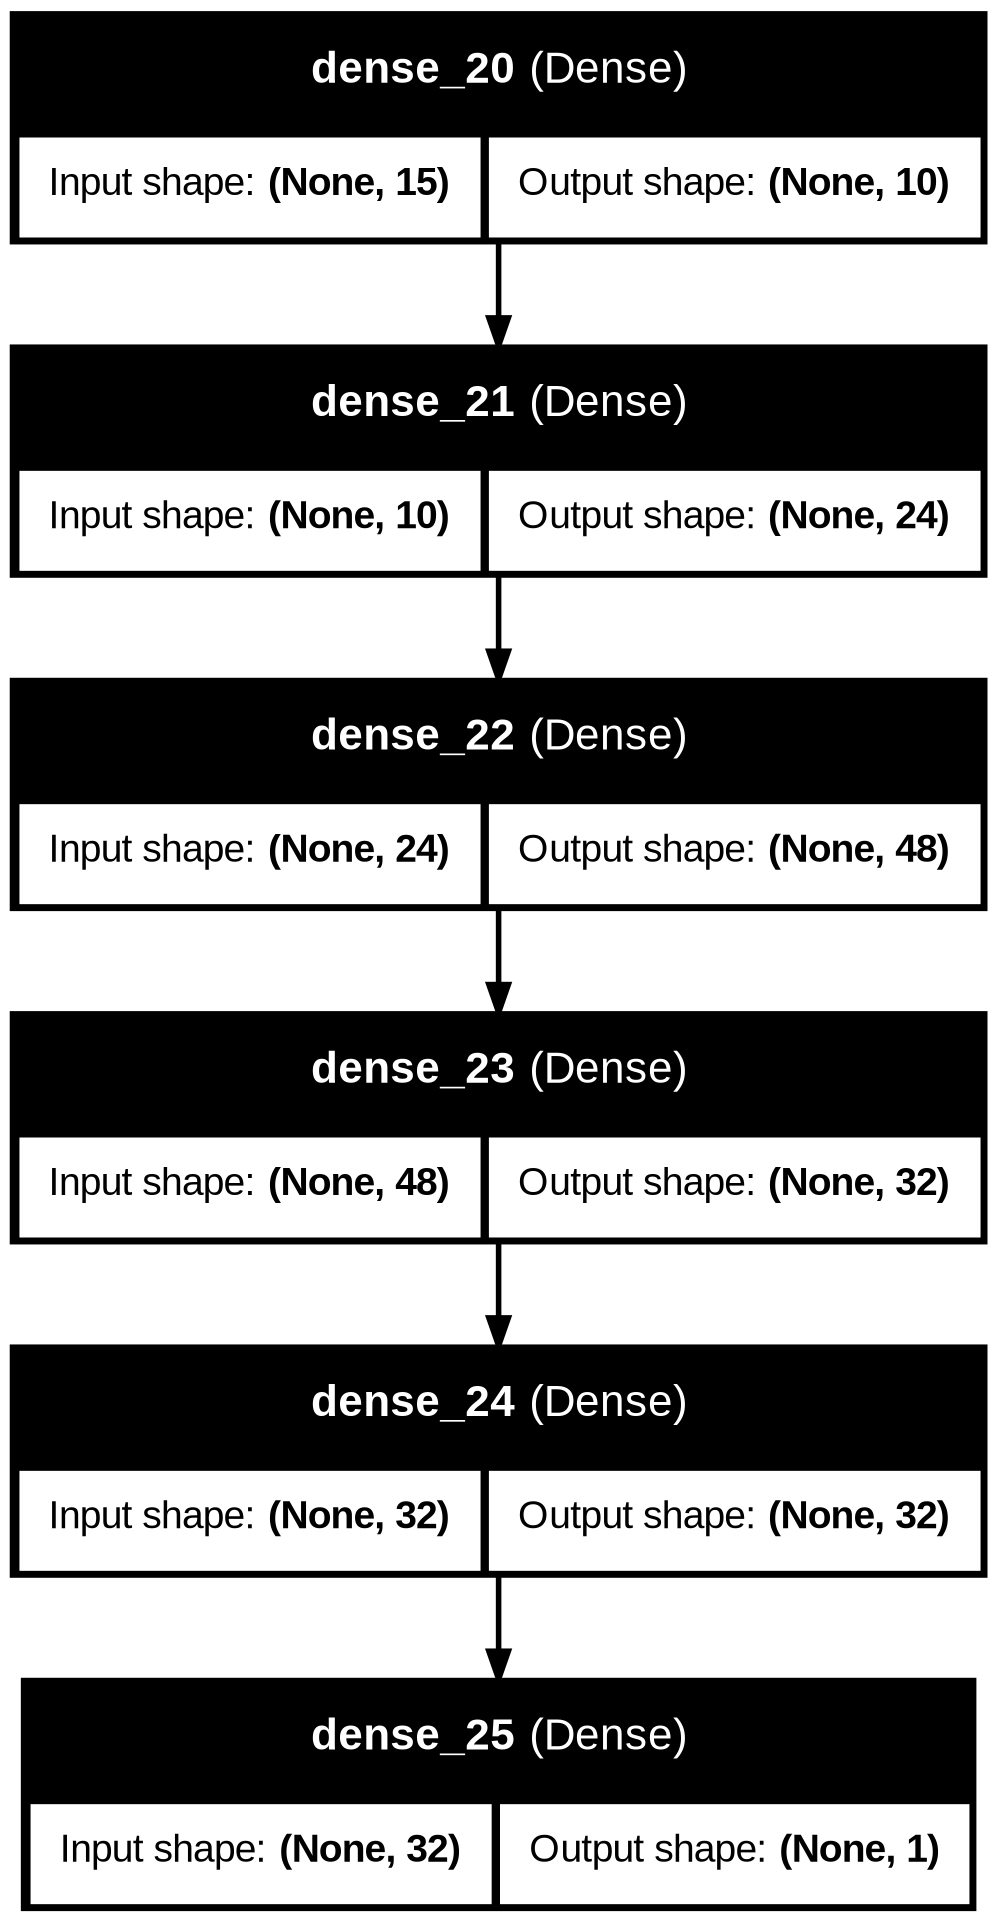

In [12]:
# Add layers after input layer (execute this cell) (0.5 Points)
# CELL 9
# run only, stacks 5 tahn hidden layers
model3 = Sequential()
model3.add(Dense(units = 10, kernel_initializer = 'uniform', activation = 'tanh', input_dim = 15))
model3.add(Dense(units = 24, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 48, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 32, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 32, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 1, kernel_initializer = 'uniform', activation = 'sigmoid'))
model3.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])
plot_model(model3, to_file='model_plot.png', show_shapes=True, show_layer_names=True)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


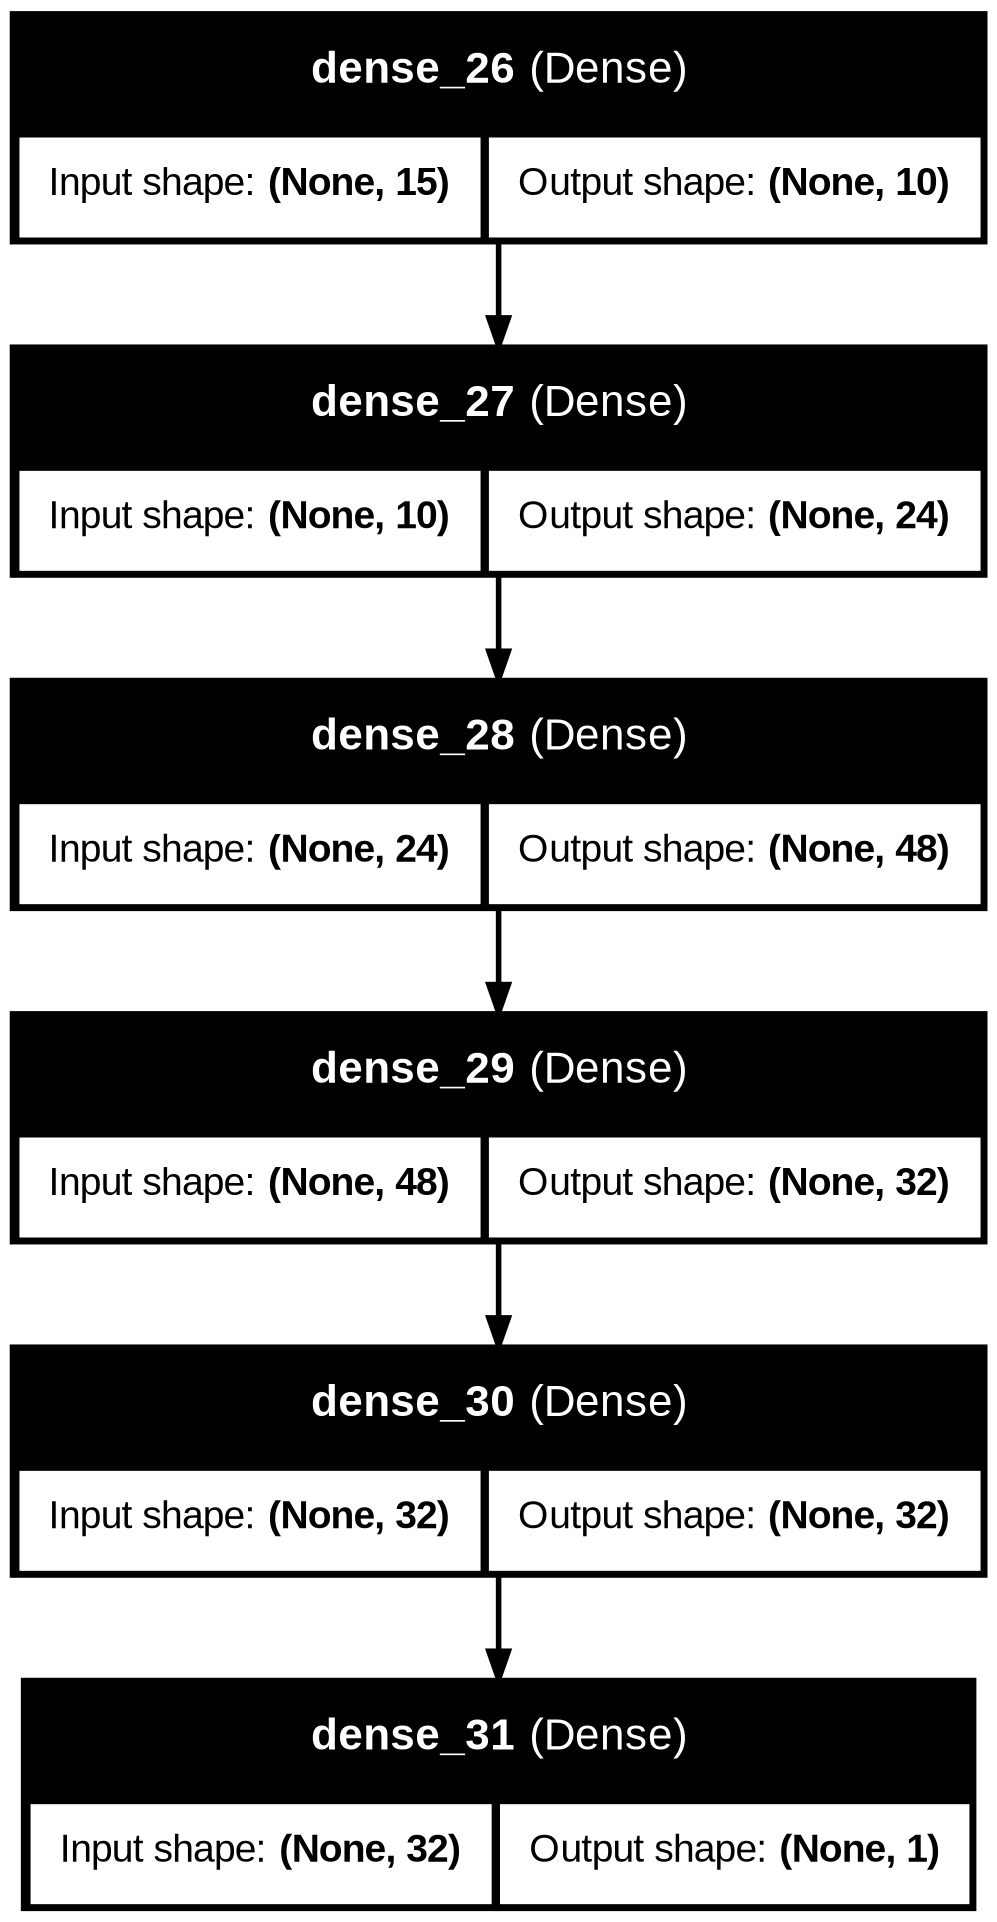

In [13]:
# Change optimizer to SGD (1.0 Points)
# CELL 10
# rebuilds model 3 link CELL 9
model3 = Sequential()
model3.add(Dense(units = 10, kernel_initializer = 'uniform', activation = 'tanh', input_dim = 15))
model3.add(Dense(units = 24, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 48, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 32, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 32, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 1, kernel_initializer = 'uniform', activation = 'sigmoid'))
model3.compile(optimizer = 'sgd', loss = 'binary_crossentropy', metrics = ['accuracy'])
plot_model(model3, to_file='model_plot.png', show_shapes=True, show_layer_names=True)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


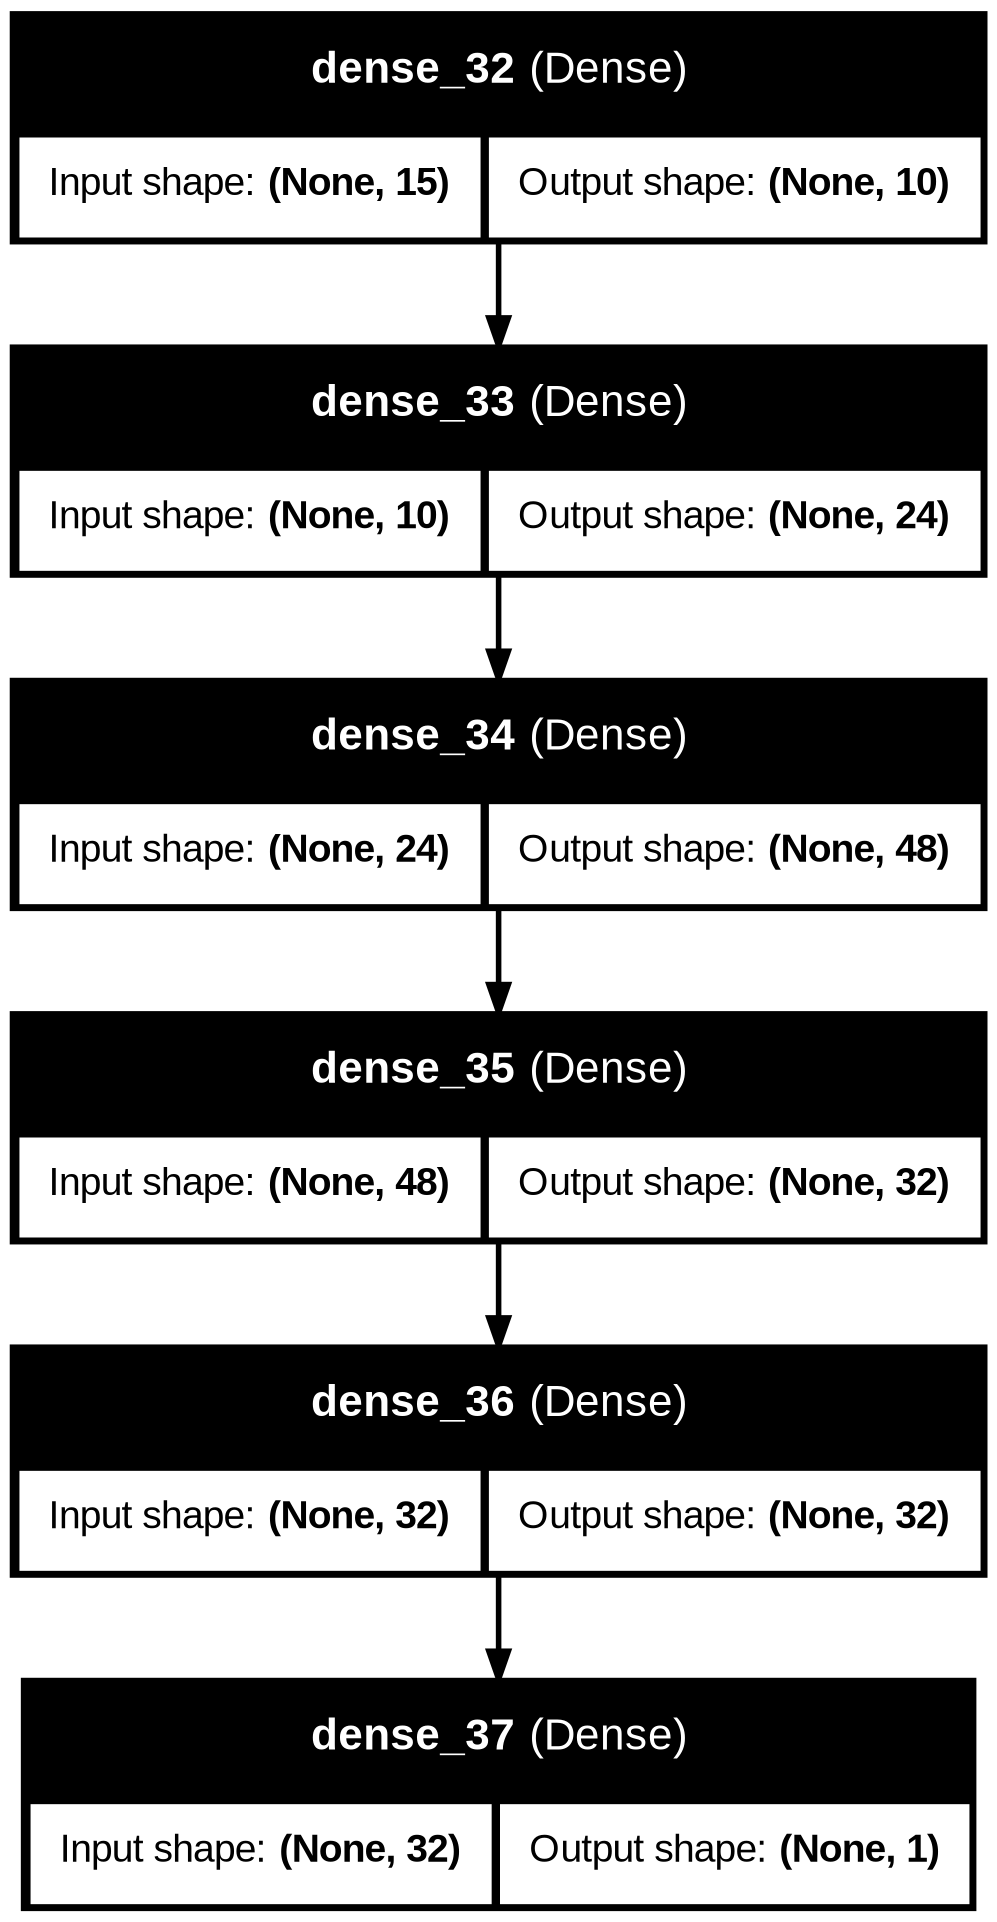

In [14]:
# Change optimizer to RMSprop (1.0 Points)
# CELL 11
# RMSprop keeps moving average converges faster than SGD
model3 = Sequential()
model3.add(Dense(units = 10, kernel_initializer = 'uniform', activation = 'tanh', input_dim = 15))
model3.add(Dense(units = 24, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 48, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 32, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 32, kernel_initializer = 'uniform', activation = 'tanh'))
model3.add(Dense(units = 1, kernel_initializer = 'uniform', activation = 'sigmoid'))
model3.compile(optimizer = 'rmsprop', loss = 'binary_crossentropy', metrics = ['accuracy'])
plot_model(model3, to_file='model_plot.png', show_shapes=True, show_layer_names=True)


#Reflection

- Question 1 (1.0 Points): How do you think activation functions affect Neural Networks?

- Question 2 (1.0 Points): How do you think optimizers affect Neural Networks?

ANSWER 1 — Question 1: How do you think activation functions affect Neural Networks?

Activation functions decide whether a neuron fires and how strongly. Without them, a stack of linear layers collapses into one big linear function, so the network could only learn straight-line relationships no matter how many layers it has. Non-linear activations like ReLU, tanh, and sigmoid break that, letting the model learn curves and complex patterns. ReLU is fast and avoids vanishing gradients on the positive side, which is why it is the default for hidden layers. Sigmoid squashes outputs to 0-1, which fits binary classification and probability-style outputs. Tanh centers values around zero, which can speed convergence in some cases. The choice changes what the network can represent and how easily it trains.

ANSWER 2 — Question 2: How do you think optimizers affect Neural Networks?

Optimizers control how the network updates its weights after each batch. SGD takes a fixed-size step in the direction of the gradient, which is simple but can be slow or zigzag on uneven loss surfaces. Adam adapts the step size per parameter using estimates of gradient momentum and variance, so it usually converges faster and needs less tuning. RMSprop is in between — it scales steps using a moving average of squared gradients to damp large updates without Adam's momentum term. In this lab we saw the same model train under all three, and the final accuracy and loss differed because each optimizer follows a different path to the minimum. A poor optimizer choice can mean longer training or getting stuck in a worse spot, even with a well-designed network.

